<a href="https://colab.research.google.com/github/amnam4751-sys/HAR-Walking-Recognition-/blob/main/PRIVATE_DATASET_IOT_Human_activity_walking_DR_ephin_(_29_10_2026).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

Saving Acceleration with g 2026-10-28 17-16-35.zip to Acceleration with g 2026-10-28 17-16-35.zip
Uploaded: ['Acceleration with g 2026-10-28 17-16-35.zip']


In [ ]:
import zipfile, os

zip_name = "Acceleration with g 2026-10-28 17-16-35.zip"
with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall("phyphox_data")

for f in os.listdir("phyphox_data"):
    print(f)

meta
Raw Data.csv


In [ ]:
import pandas as pd

df = pd.read_csv("phyphox_data/Raw Data.csv")
print("Rows and columns:", df.shape)
print(df.columns.tolist())
print(df.head())

Rows and columns: (50303, 5)
['Time (s)', 'Acceleration x (m/s^2)', 'Acceleration y (m/s^2)', 'Acceleration z (m/s^2)', 'Absolute acceleration (m/s^2)']
   Time (s)  Acceleration x (m/s^2)  Acceleration y (m/s^2)  \
0  0.042489                0.837488              -11.614761   
1  0.044874                1.110270              -11.475977   
2  0.047259                1.337588              -11.296515   
3  0.049643                1.552942              -11.102697   
4  0.052028                1.737189              -10.868200   

   Acceleration z (m/s^2)  Absolute acceleration (m/s^2)  
0               -3.120241                      12.055703  
1               -3.172883                      11.958174  
2               -3.065206                      11.781167  
3               -2.816352                      11.559124  
4               -2.490928                      11.284517  


In [ ]:
# 1. Check duration and sampling rate
duration = df["Time (s)"].iloc[-1] - df["Time (s)"].iloc[0]
print("Duration (s):", round(duration, 1))
print("Samples per second:", round(len(df) / duration))

# 2. Trim 3 s from the start and end (phone settling in the pocket)
start = df["Time (s)"].iloc[0] + 3
end = df["Time (s)"].iloc[-1] - 3
clean = df[(df["Time (s)"] >= start) & (df["Time (s)"] <= end)].copy()

# 3. Make time start at 0
clean["Time (s)"] = clean["Time (s)"] - clean["Time (s)"].iloc[0]

# 4. Add the label column
clean["label"] = "walking"

# 5. Save
clean.to_csv("walk_dataset.csv", index=False)
print("Saved rows:", len(clean))
print(clean.head())

Duration (s): 120.0
Samples per second: 419
Saved rows: 47787
      Time (s)  Acceleration x (m/s^2)  Acceleration y (m/s^2)  \
1258  0.000000               -2.115255               -5.436493   
1259  0.002385               -2.177469               -5.551349   
1260  0.004770               -2.261217               -5.673382   
1261  0.007154               -2.304288               -5.785845   
1262  0.009539               -2.366502               -5.927022   

      Acceleration z (m/s^2)  Absolute acceleration (m/s^2)    label  
1258                1.337588                       5.984889  walking  
1259                1.299303                       6.103034  walking  
1260                1.268196                       6.237683  walking  
1261                1.220340                       6.346257  walking  
1262                1.227518                       6.498978  walking  


In [ ]:
from google.colab import files
files.download("walk_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

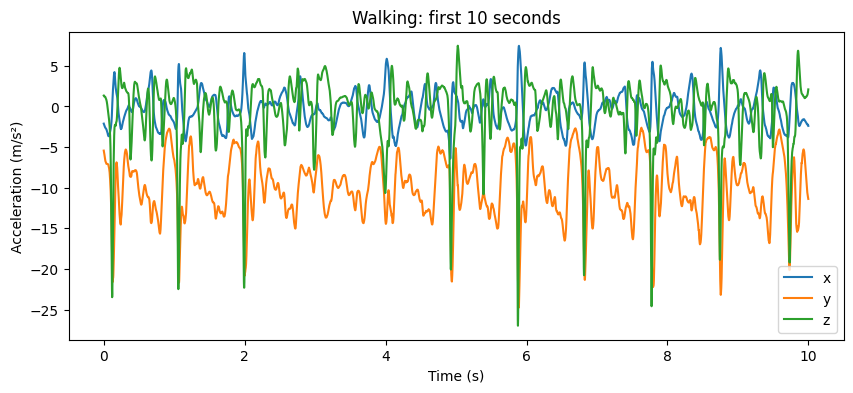

In [ ]:
import matplotlib.pyplot as plt

# First 10 seconds of the cleaned data
seg = clean[clean["Time (s)"] <= 10]

plt.figure(figsize=(10, 4))
plt.plot(seg["Time (s)"], seg["Acceleration x (m/s^2)"], label="x")
plt.plot(seg["Time (s)"], seg["Acceleration y (m/s^2)"], label="y")
plt.plot(seg["Time (s)"], seg["Acceleration z (m/s^2)"], label="z")
plt.xlabel("Time (s)")
plt.ylabel("Acceleration (m/s²)")
plt.title("Walking: first 10 seconds")
plt.legend()
plt.show()

In [ ]:
print("Dataset length (s):", round(clean["Time (s)"].iloc[-1], 1))
print("Rows:", len(clean))

Dataset length (s): 114.0
Rows: 47787


In [ ]:
full = df.copy()
full["Time (s)"] = full["Time (s)"] - full["Time (s)"].iloc[0]
full["label"] = "walking"
full.to_csv("walk_dataset_full.csv", index=False)

from google.colab import files
files.download("walk_dataset_full.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
full = df.copy()
full["Time (s)"] = full["Time (s)"] - full["Time (s)"].iloc[0]
full["label"] = "walking"
full.to_csv("walk_dataset_full.csv", index=False)

print("Dataset length (s):", round(full["Time (s)"].iloc[-1], 1))
print("Rows:", len(full))

from google.colab import files
files.download("walk_dataset_full.csv")

Dataset length (s): 120.0
Rows: 50303


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

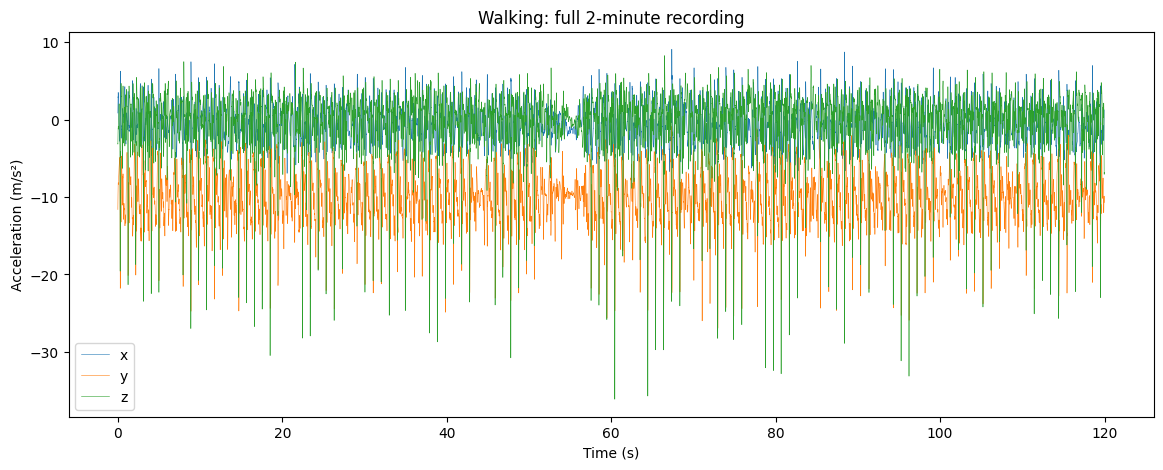

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(full["Time (s)"], full["Acceleration x (m/s^2)"], label="x", linewidth=0.4)
plt.plot(full["Time (s)"], full["Acceleration y (m/s^2)"], label="y", linewidth=0.4)
plt.plot(full["Time (s)"], full["Acceleration z (m/s^2)"], label="z", linewidth=0.4)
plt.xlabel("Time (s)")
plt.ylabel("Acceleration (m/s²)")
plt.title("Walking: full 2-minute recording")
plt.legend()
plt.show()

In [2]:
import pandas as pd
from google.colab import files
import io

# Upload raw walking sensor data
uploaded = files.upload()

# Read the CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# Display the dataset
print("PRIVATE WALKING DATASET")
print("First 5 rows:")
display(df.head())

# Show columns and data types
print("Dataset information:")
df.info()

# Check dataset size
print("Dataset shape:", df.shape)


Saving Raw Data.csv to Raw Data.csv
PRIVATE WALKING DATASET
First 5 rows:


,Time (s),Acceleration x (m/s^2),Acceleration y (m/s^2),Acceleration z (m/s^2),Absolute acceleration (m/s^2)
0,0.042489,0.837488,-11.614761,-3.120241,12.055703
1,0.044874,1.110270,-11.475977,-3.172883,11.958174
2,0.047259,1.337588,-11.296515,-3.065206,11.781167
3,0.049643,1.552942,-11.102697,-2.816352,11.559124
4,0.052028,1.737189,-10.868200,-2.490928,11.284517


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50303 entries, 0 to 50302
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Time (s)                       50303 non-null  float64
 1   Acceleration x (m/s^2)         50303 non-null  float64
 2   Acceleration y (m/s^2)         50303 non-null  float64
 3   Acceleration z (m/s^2)         50303 non-null  float64
 4   Absolute acceleration (m/s^2)  50303 non-null  float64
dtypes: float64(5)
memory usage: 1.9 MB
Dataset shape: (50303, 5)


In [3]:
# STEP 4: DATA QUALITY CHECK AND CLEANING

# Make a copy of the original dataset
clean_df = df.copy()

# Check missing values
print("Missing values:")
print(clean_df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:")
print(clean_df.duplicated().sum())

# Remove duplicate rows
clean_df = clean_df.drop_duplicates()

# Sort data by time
clean_df = clean_df.sort_values("Time (s)")

# Check time range
print("\nRecording starts at:", clean_df["Time (s)"].min(), "seconds")
print("Recording ends at:", clean_df["Time (s)"].max(), "seconds")

# Check acceleration statistics
print("\nAcceleration summary:")
display(clean_df.describe())

print("\nCleaned dataset shape:", clean_df.shape)

Missing values:
Time (s)                         0
Acceleration x (m/s^2)           0
Acceleration y (m/s^2)           0
Acceleration z (m/s^2)           0
Absolute acceleration (m/s^2)    0
dtype: int64

Duplicate rows:
0

Recording starts at: 0.042488968 seconds
Recording ends at: 120.0042608 seconds

Acceleration summary:


,Time (s),Acceleration x (m/s^2),Acceleration y (m/s^2),Acceleration z (m/s^2),Absolute acceleration (m/s^2)
count,50303.000000,50303.000000,50303.000000,50303.000000,50303.000000
mean,60.023241,-0.634504,-9.936985,-0.210716,10.675076
std,34.631021,2.146776,3.547590,3.913578,4.212276
min,0.042489,-6.946364,-26.931219,-36.102909,0.997219
25%,30.032763,-2.096113,-12.149557,-1.313660,8.048703
50%,60.023176,-0.677169,-9.796216,0.653241,10.211643
75%,90.013679,0.605384,-7.592426,1.952543,12.701280
max,120.004261,9.073584,-0.880559,8.252846,42.232805



Cleaned dataset shape: (50303, 5)


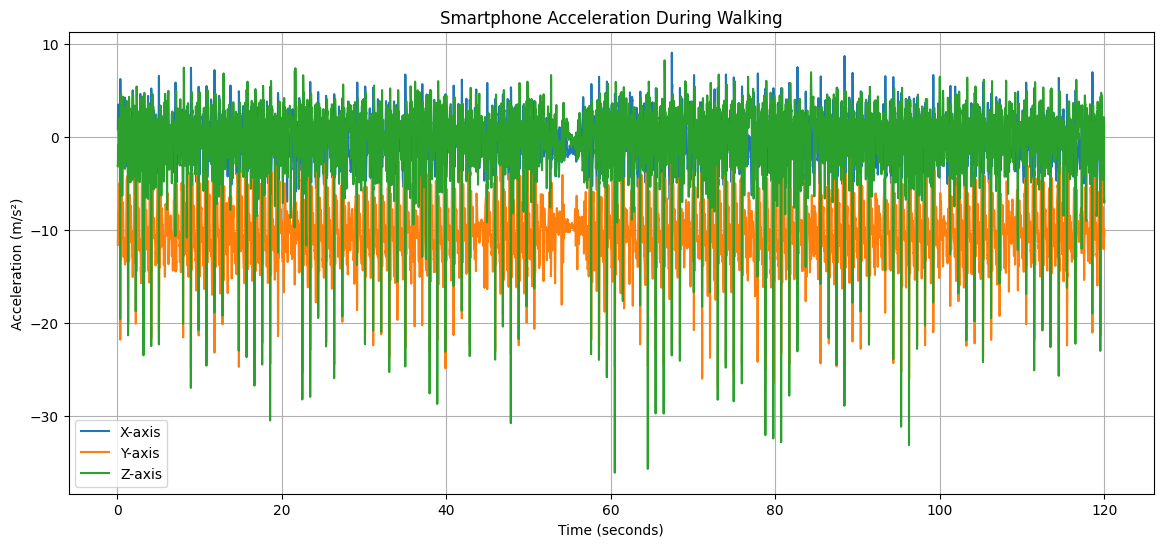

In [4]:
import matplotlib.pyplot as plt

# Plot acceleration on all three axes
plt.figure(figsize=(14, 6))

plt.plot(clean_df["Time (s)"],
         clean_df["Acceleration x (m/s^2)"],
         label="X-axis")

plt.plot(clean_df["Time (s)"],
         clean_df["Acceleration y (m/s^2)"],
         label="Y-axis")

plt.plot(clean_df["Time (s)"],
         clean_df["Acceleration z (m/s^2)"],
         label="Z-axis")

plt.title("Smartphone Acceleration During Walking")
plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (m/s²)")
plt.legend()
plt.grid(True)
plt.show()